# Piano-error model: evaluation results

Explores one evaluation run from `eval/runs/`: headline numbers, per-piece and per-take tables,
the three charts, every note where the model disagrees with the labels, alignment plots, and a
comparison between two runs.

**Kernel:** choose **Python (piano-eval .venv)** (Kernel → Change Kernel). It is the project's own
`.venv`, so it has the model and harness dependencies.

**Typical loop** (details in `eval/README.md`): drop new recordings into `recordings/eval-interviews/raw/` →
`python -m eval.cli sync` → label the new rows in the shared sheet → export it as CSV →
`python -m eval.cli evaluate --sheet <export.csv>` → re-run this notebook (it opens the latest run).

In [1]:
# 1. Setup: work from the repo root so `eval` and the model modules import
import os, sys, json, subprocess
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "eval" / "manifest.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from eval.plots import load_run, plot_overview, plot_confusion, plot_note_map
from eval.runs import RUNS_DIR

%matplotlib inline
pd.set_option("display.max_rows", 200)
print("repo:", ROOT)

repo: /Users/thomaschin/Documents/GitHub/School/automatic-piano-evaluation-hmm


## 2. (Optional) start a new evaluation run
Takes several minutes (about 15 s per take, longer for Canon). Leave `RUN_NEW = False` to just explore existing runs.

In [2]:
RUN_NEW = False
RUN_ARGS = ["--split", "dev"]          # e.g. ["--piece", "canon_lh"] or ["--take", "2ode-1h-wrong"]

if RUN_NEW:
    proc = subprocess.run([sys.executable, "-m", "eval.cli", "run", *RUN_ARGS],
                          capture_output=True, text=True)
    print(proc.stdout[-4000:])
    if proc.returncode:
        print(proc.stderr[-4000:])

## 3. Pick a run
`RUN = None` uses the most recent run. Otherwise paste a run name (or any unique part of it) from the table.

In [3]:
RUN = None

runs = sorted(p for p in RUNS_DIR.iterdir() if (p / "metrics.json").exists())
listing = []
for p in runs:
    meta = json.loads((p / "meta.json").read_text())
    o = json.loads((p / "metrics.json").read_text())["overall"]
    listing.append({"run": p.name, "model": meta["model"], "split": meta["split"], "takes": o["n_takes"],
                    "error F1": o["error"]["f1"], "precision": o["error"]["precision"],
                    "recall": o["error"]["recall"],
                    "clean perfect takes": f"{o['perfect_takes']['clean']}/{o['perfect_takes']['n']}"})
display(pd.DataFrame(listing).set_index("run").round(3))

if RUN is None:
    run_dir = runs[-1]
else:
    matches = [p for p in runs if RUN in p.name]
    assert len(matches) == 1, f"'{RUN}' matches {len(matches)} runs"
    run_dir = matches[0]
metrics, rows = load_run(run_dir)
meta = json.loads((run_dir / "meta.json").read_text())
notes = pd.DataFrame(rows)
notes["label_ok"] = notes["label_ok"] == "True"
print("Using run:", run_dir.name)

,model,split,takes,error F1,precision,recall,clean perfect takes
run,,,,,,,
20261028-162845_v2_0e0f184-dirty,v2,dev,1,NaN,NaN,NaN,1/1
20261028-162903_v2_0e0f184-dirty,v2,dev,1,NaN,NaN,NaN,1/1
20261029-111844_v2_0e0f184-dirty,v2,dev,32,0.619,0.5,0.811,7/17


Using run: 20261029-111844_v2_0e0f184-dirty


## 4. Headline

In [4]:
o = metrics["overall"]
def f(x): return "–" if x is None else f"{x:.2f}"
display(Markdown(
    f"**Error F1 {f(o['error']['f1'])}** · precision {f(o['error']['precision'])} · recall {f(o['error']['recall'])}  \n"
    f"{o['n_takes']} takes, {o['n_notes']} notes · perfect takes with zero false alarms: "
    f"**{o['perfect_takes']['clean']}/{o['perfect_takes']['n']}** · pass/fail accuracy {f(o['pass_fail_accuracy'])}  \n"
    f"Played-pitch accuracy on caught wrong notes: {f(o['played_pitch_accuracy'])} (n={o['played_pitch_n']})  \n"
    f"Model: `{meta['model']}` at commit `{meta['git']['commit']}`{' (uncommitted changes)' if meta['git']['dirty'] else ''}  \n"
    f"Error types the model can't detect yet: {', '.join(o['unsupported_types']) or 'none'}"
    + (f"  \n**Failed takes:** {', '.join(o['failed_takes'])}" if o["failed_takes"] else "")))

**Error F1 0.62** · precision 0.50 · recall 0.81  
32 takes, 814 notes · perfect takes with zero false alarms: **7/17** · pass/fail accuracy 0.62  
Played-pitch accuracy on caught wrong notes: 0.86 (n=29)  
Model: `v2` at commit `0e0f184` (uncommitted changes)  
Error types the model can't detect yet: early, extra, held_long, late

## 5. By piece

In [5]:
def summary_row(b):
    pt = b["perfect_takes"]
    return {"takes": b["n_takes"], "notes": b["n_notes"],
            "error P": b["error"]["precision"], "error R": b["error"]["recall"], "error F1": b["error"]["f1"],
            "wrong-pitch F1": b["wrong_pitch"]["f1"], "missed F1": b["missed"]["f1"],
            "combined F1": b["combined"]["f1"],
            "false alarms": b["error"]["fp"], "missed errors": b["error"]["fn"],
            "clean perfect": f"{pt['clean']}/{pt['n']}" if pt["n"] else "",
            "pass/fail acc": b["pass_fail_accuracy"]}

by_piece = pd.DataFrame({p: summary_row(b) for p, b in metrics["by_piece"].items()}).T
by_piece.loc["OVERALL"] = summary_row(o)
display(by_piece.infer_objects().round(2))

,takes,notes,error P,error R,error F1,wrong-pitch F1,missed F1,combined F1,false alarms,missed errors,clean perfect,pass/fail acc
c_major_both,2,32,0.00,NaN,0.00,NaN,0.00,0.00,1,0,1/2,0.50
c_major_rh,4,32,0.12,1.00,0.22,0.29,0.00,0.22,7,0,2/3,0.75
canon_both,3,216,0.65,0.74,0.69,0.58,0.40,0.68,9,6,,1.00
canon_lh,4,256,1.00,0.95,0.97,0.97,NaN,0.82,0,1,,0.50
e_major_both,2,32,0.00,NaN,0.00,0.00,0.00,0.00,4,0,0/2,0.00
e_major_rh,2,16,0.00,NaN,0.00,0.00,NaN,0.00,2,0,0/2,0.00
e_major_rh_down,1,8,0.00,NaN,0.00,0.00,0.00,0.00,6,0,0/1,0.00
ode_harmony,3,57,1.00,1.00,1.00,1.00,NaN,1.00,0,0,1/1,1.00
ode_melody,11,165,0.26,0.62,0.37,0.12,0.40,0.36,14,3,3/6,0.73
OVERALL,32,814,0.50,0.81,0.62,0.60,0.33,0.58,43,10,7/17,0.62


## 6. Charts
**Overview:** precision / recall / F1 per piece, and recall by error type. Pieces with no labeled errors show only their false-alarm count.

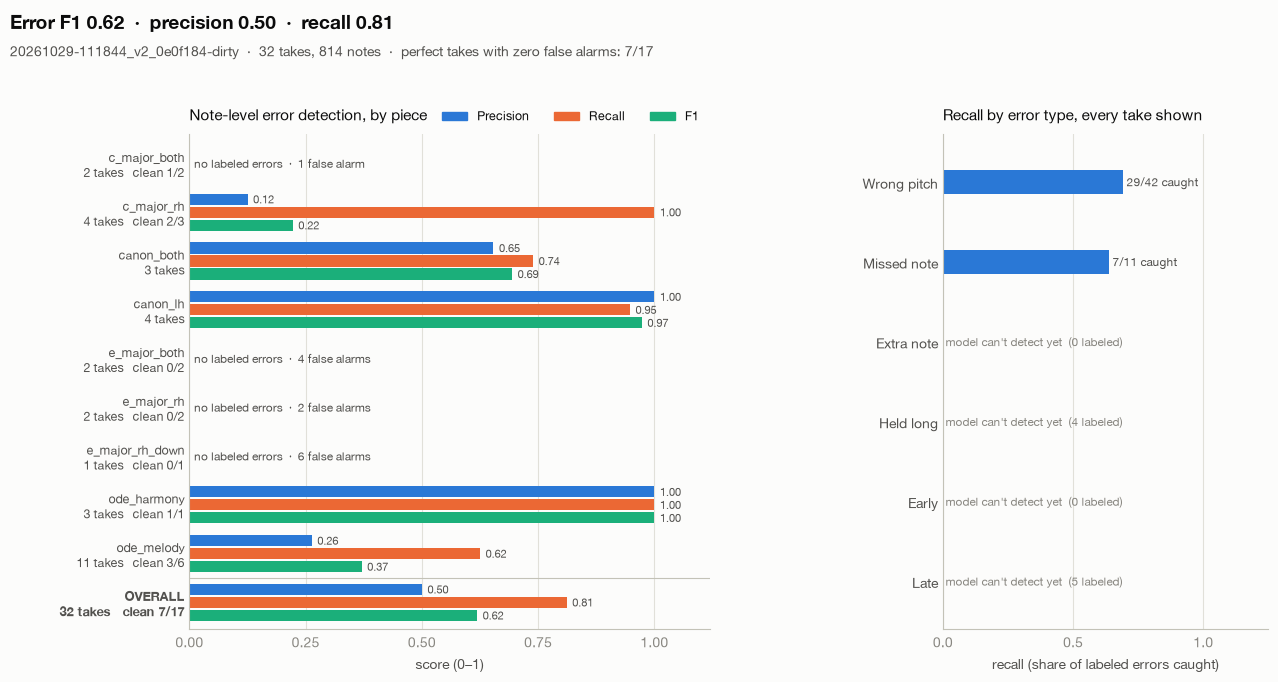

In [6]:
fig = plot_overview(metrics, run_dir.name); display(fig); plt.close(fig)

**Confusion:** your label (rows) vs what the model said (columns), row-normalized.

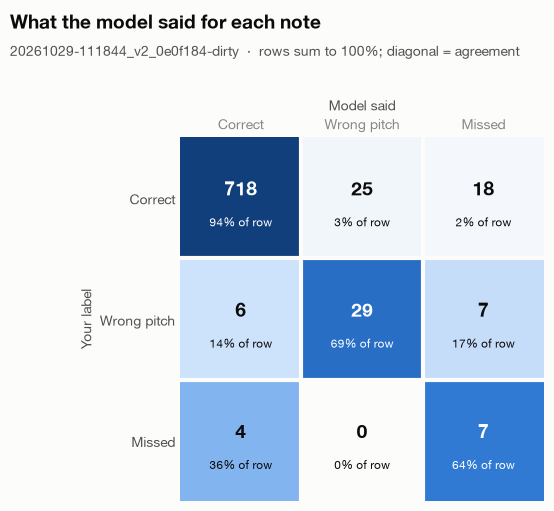

In [7]:
fig = plot_confusion(metrics, run_dir.name); display(fig); plt.close(fig)

**Note map:** one row per take, one cell per score note (score order, measure lines).
Gray = agree & correct · blue = error caught · orange = false alarm · green = error missed ·
× = caught with the wrong error type · • = labeled held/early/late.

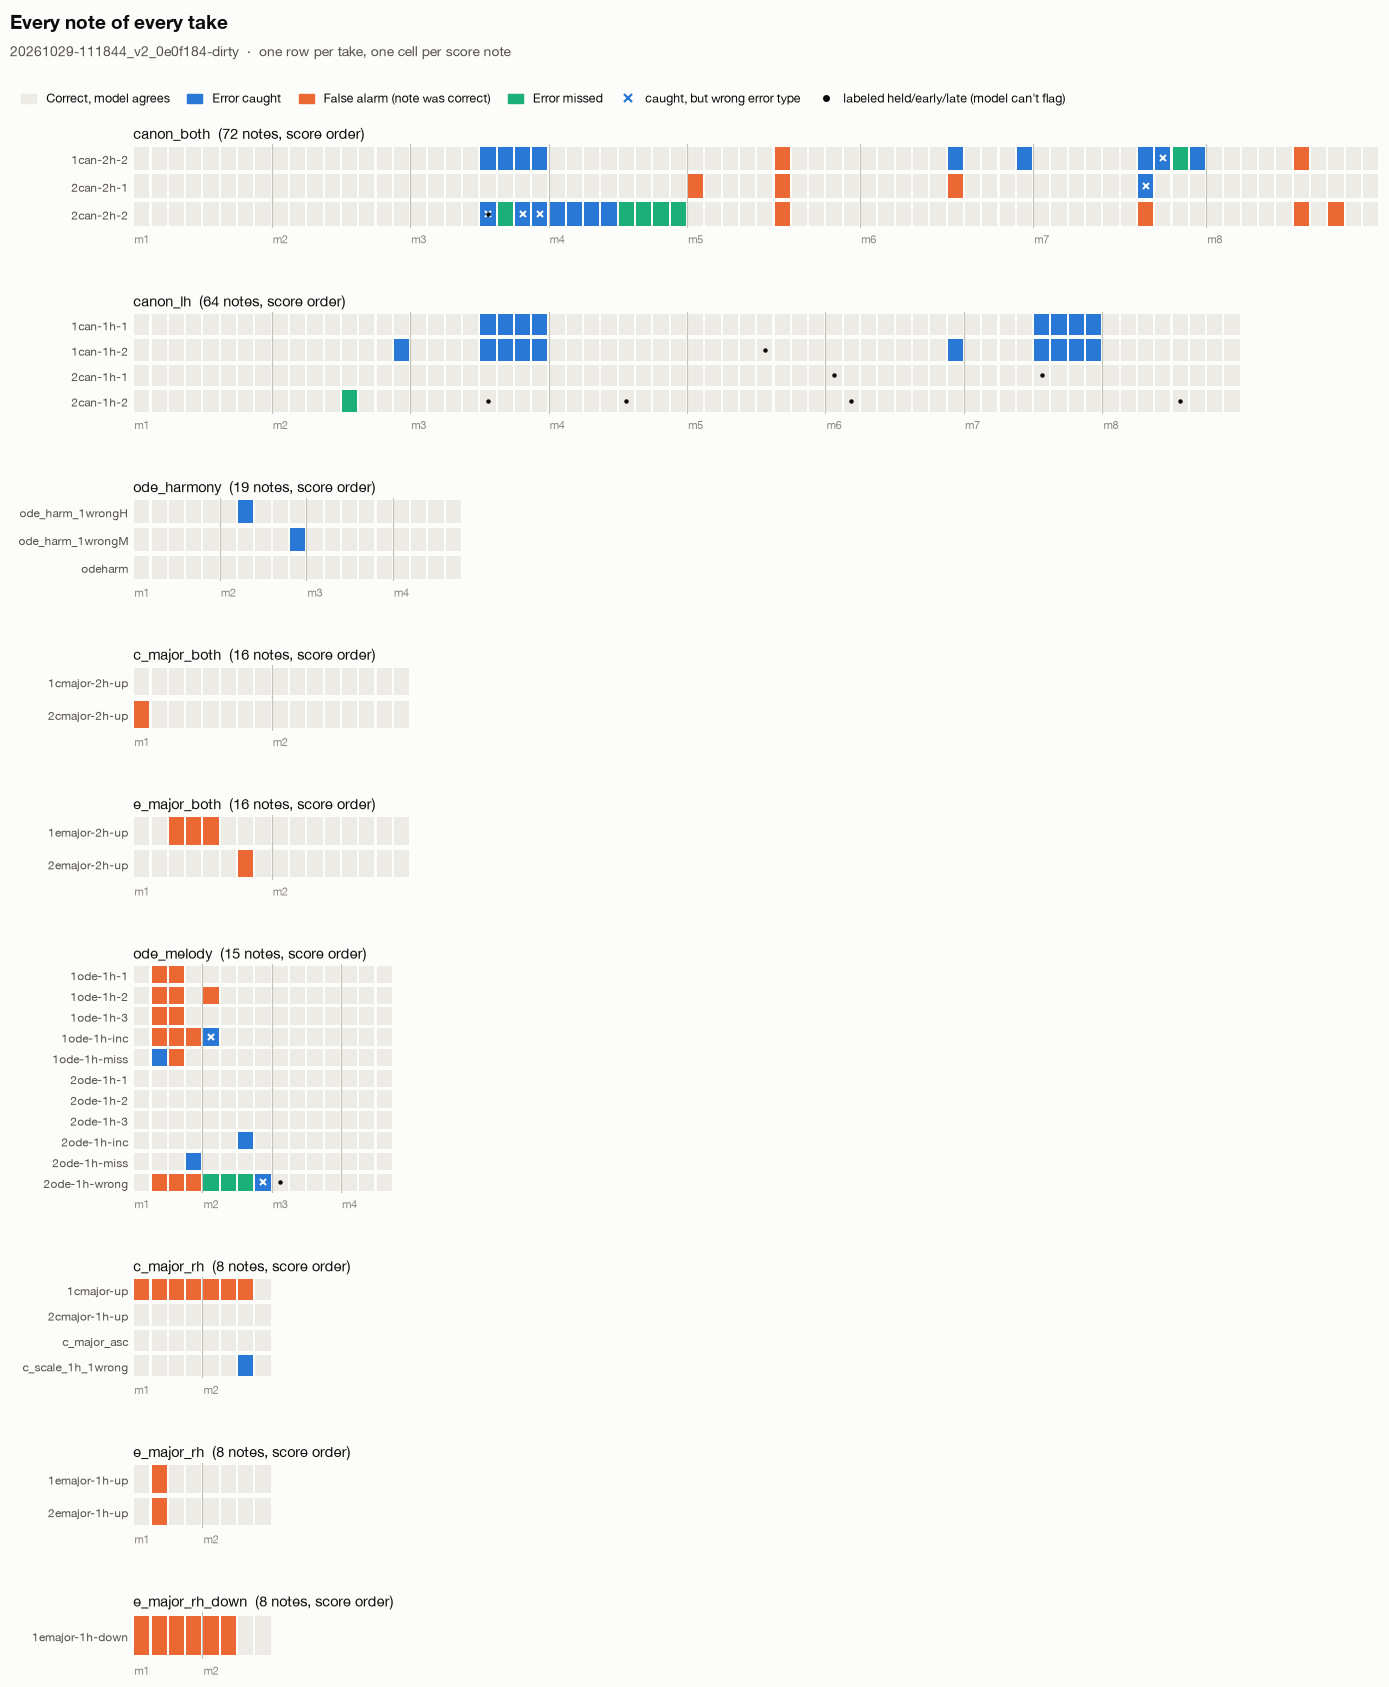

In [8]:
fig = plot_note_map(rows, run_dir.name); display(fig); plt.close(fig)

## 7. By take
Sorted worst first (most false alarms + missed errors).

In [9]:
by_take = pd.DataFrame({t: summary_row(b) for t, b in metrics["by_take"].items()}).T
by_take.insert(0, "piece", notes.groupby("take")["piece"].first())
by_take["problems"] = by_take["false alarms"] + by_take["missed errors"]
display(by_take.sort_values(["problems", "piece"], ascending=[False, True])
        [["piece", "notes", "false alarms", "missed errors", "error F1", "pass/fail acc"]].infer_objects().round(2))

,piece,notes,false alarms,missed errors,error F1,pass/fail acc
2can-2h-2,canon_both,72,4,5,0.61,1.0
1cmajor-up,c_major_rh,8,7,0,0.00,0.0
1emajor-1h-down,e_major_rh_down,8,6,0,0.00,0.0
2ode-1h-wrong,ode_melody,15,3,3,0.25,1.0
1can-2h-2,canon_both,72,2,1,0.86,1.0
2can-2h-1,canon_both,72,3,0,0.40,1.0
1emajor-2h-up,e_major_both,16,3,0,0.00,0.0
1ode-1h-2,ode_melody,15,3,0,0.00,0.0
1ode-1h-inc,ode_melody,15,3,0,0.40,1.0
1ode-1h-1,ode_melody,15,2,0,0.00,0.0


## 8. Every disagreement
Notes where the model's label or flags differ from yours. Narrow it with `PIECE` / `TAKE`.
`gold_played` / `pred_played` are MIDI numbers for wrong-pitch notes (60 = C4).

In [10]:
PIECE = None        # e.g. "ode_melody"
TAKE = None         # e.g. "1ode-1h-2"

bad = notes[~notes["label_ok"] | (notes["gold_flags"] != notes["pred_flags"])]
if PIECE: bad = bad[bad["piece"] == PIECE]
if TAKE: bad = bad[bad["take"] == TAKE]
def kind(r):
    if r["gold"] == r["pred"]: return "flag only"
    if r["gold"] == "correct": return "false alarm"
    if r["pred"] == "correct": return "missed error"
    return "wrong error type"
bad = bad.assign(kind=bad.apply(kind, axis=1))
print(bad["kind"].value_counts().to_string(), "\n")
display(bad[["take", "note_id", "pitch", "measure", "beat", "gold", "pred",
             "gold_played", "pred_played", "gold_flags", "onset_s", "kind"]].reset_index(drop=True))

kind
false alarm         43
missed error        10
flag only            8
wrong error type     7 



,take,note_id,pitch,measure,beat,gold,pred,gold_played,pred_played,gold_flags,onset_s,kind
0,1can-1h-2,LH37,A2,5,3.0,correct,correct,,45,late,18.204,flag only
1,1can-2h-2,RH2,E5,5,3.0,correct,missed,,,,17.554,false alarm
2,1can-2h-2,LH54,A2,7,3.5,wrong_pitch,missed,57,,,26.262,wrong error type
3,1can-2h-2,LH55,D3,7,4.0,wrong_pitch,correct,62,50,,26.68,missed error
4,1can-2h-2,RH8,C#5,8,3.0,correct,missed,,,,29.466,false alarm
5,2can-1h-1,LH41,B2,6,1.0,correct,correct,,47,held_long,40.658,flag only
6,2can-1h-1,LH53,D2,7,3.0,correct,correct,,38,late,53.081,flag only
7,2can-2h-1,RH1,F#5,5,1.0,correct,missed,,,,31.556,false alarm
8,2can-2h-1,RH2,E5,5,3.0,correct,missed,,,,35.689,false alarm
9,2can-2h-1,RH4,C#5,6,3.0,correct,wrong_pitch,,76,,44.629,false alarm


## 9. Where do false alarms cluster?
Counts per note position across all takes of each piece. A note that is a false alarm in many
takes points at a systematic model problem rather than one bad recording.

In [11]:
fa = notes[(notes["gold"] == "correct") & (notes["pred"] != "correct")]
hot = (fa.groupby(["piece", "note_id", "pitch", "measure", "beat"]).size()
         .rename("false alarms").reset_index()
         .merge(notes.groupby("piece")["take"].nunique().rename("takes of piece"), on="piece"))
display(hot.sort_values("false alarms", ascending=False).head(20).reset_index(drop=True))

,piece,note_id,pitch,measure,beat,false alarms,takes of piece
0,ode_melody,RH3,F4,1,3.0,6,11
1,ode_melody,RH2,E4,1,2.0,5,11
2,canon_both,RH2,E5,5,3.0,3,3
3,ode_melody,RH4,G4,1,4.0,2,11
4,e_major_rh,RH2,F#4,1,2.0,2,2
5,canon_both,RH8,C#5,8,3.0,2,3
6,c_major_both,RH1,C4,1,1.0,1,2
7,e_major_both,RH3,G#4,1,3.0,1,2
8,e_major_rh_down,RH6,G#4,2,2.0,1,1
9,e_major_rh_down,RH5,A4,2,1.0,1,1


## 10. Alignment plot for one take
The model's own segment plot, saved for every take during the run.

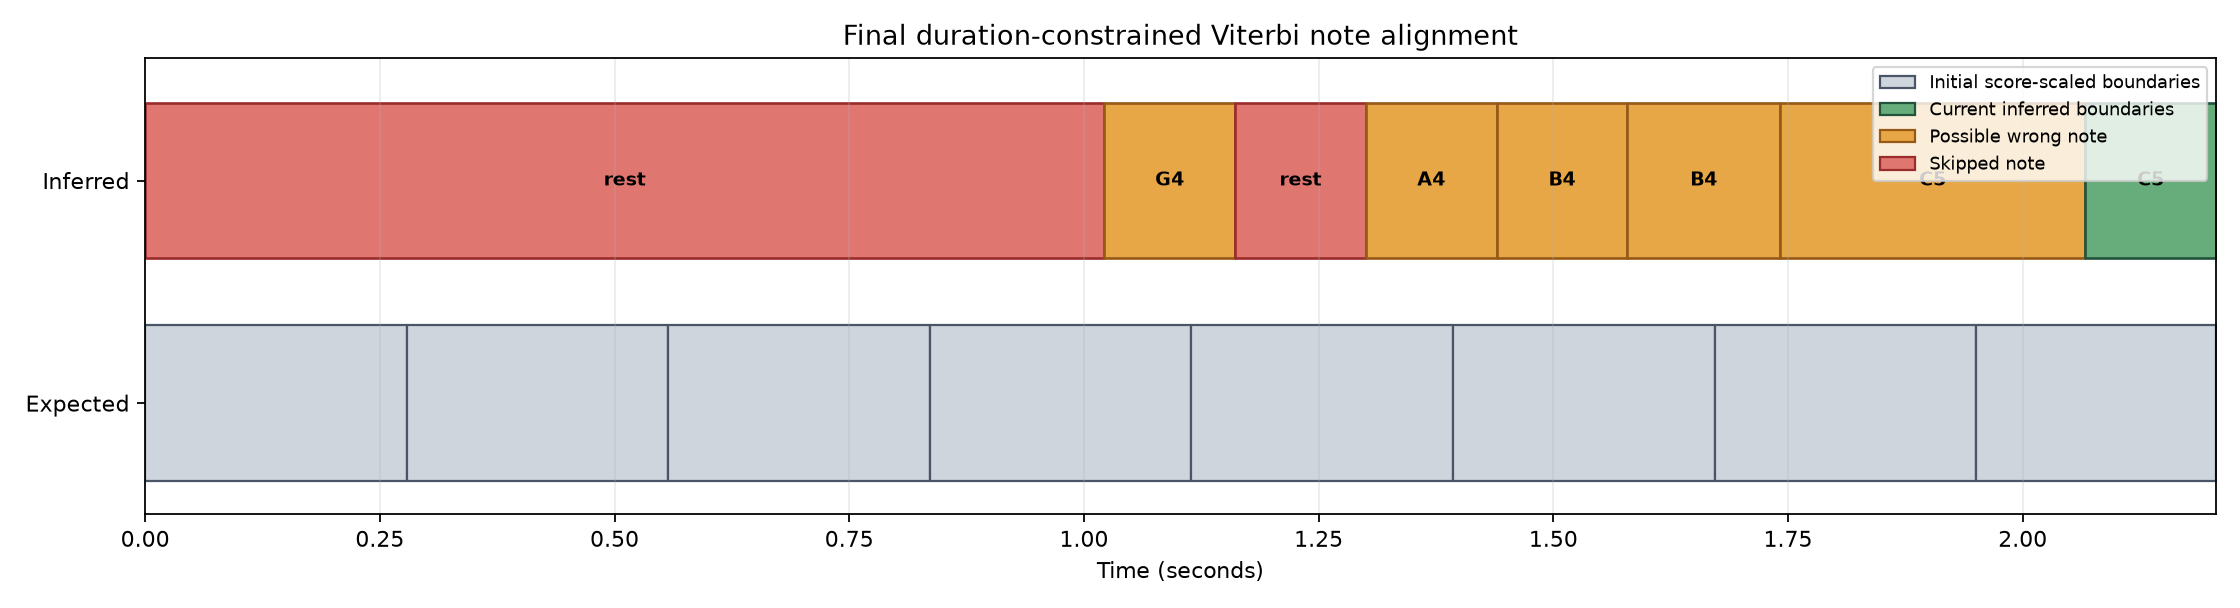

In [12]:
SHOW_TAKE = "1cmajor-up"

plot = run_dir / "takes" / SHOW_TAKE / "alignment.png"
display(Image(filename=str(plot)) if plot.exists() else Markdown(f"No alignment plot for `{SHOW_TAKE}` in this run."))

## 11. Compare two runs
Use after the model changes. `RUN_A` defaults to the second-newest run and `RUN_B` to the newest.
Score changes use each run's full take set; note flips use only takes present in both runs.

In [13]:
RUN_A, RUN_B = None, None

def pick(name, default):
    if name is None: return default
    m = [p for p in runs if name in p.name]; assert len(m) == 1, name; return m[0]

if len(runs) < 2:
    print("Only one run so far: run another evaluation to compare.")
else:
    a, b = pick(RUN_A, runs[-2]), pick(RUN_B, runs[-1])
    (ma, ra), (mb, rb) = load_run(a), load_run(b)
    print("A =", a.name, "\nB =", b.name)
    keys = ["error", "wrong_pitch", "missed", "combined"]
    table = {}
    for piece in sorted(set(ma["by_piece"]) | set(mb["by_piece"])) + ["OVERALL"]:
        ba = ma["overall"] if piece == "OVERALL" else ma["by_piece"].get(piece)
        bb = mb["overall"] if piece == "OVERALL" else mb["by_piece"].get(piece)
        row = {}
        for k in keys:
            fa_, fb_ = (ba or {}).get(k, {}).get("f1"), (bb or {}).get(k, {}).get("f1")
            row[f"{k} F1 A"], row[f"{k} F1 B"] = fa_, fb_
            row[f"{k} Δ"] = None if fa_ is None or fb_ is None else fb_ - fa_
        table[piece] = row
    display(pd.DataFrame(table).T.infer_objects().round(2))

    na, nb = pd.DataFrame(ra), pd.DataFrame(rb)
    both = na.merge(nb, on=["take", "note_id"], suffixes=("_A", "_B"))
    both = both[both["label_ok_A"] != both["label_ok_B"]]
    both["change"] = both["label_ok_B"].map({"True": "fixed", "False": "broken"})
    print(both["change"].value_counts().to_string() if len(both) else "No notes changed.")
    display(both[["take", "note_id", "pitch_A", "gold_A", "pred_A", "pred_B", "change"]].reset_index(drop=True))

A = 20261028-162903_v2_0e0f184-dirty 
B = 20261029-111844_v2_0e0f184-dirty


,error F1 A,error F1 B,error Δ,wrong_pitch F1 A,wrong_pitch F1 B,wrong_pitch Δ,missed F1 A,missed F1 B,missed Δ,combined F1 A,combined F1 B,combined Δ
c_major_both,NaN,0.00,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,NaN
c_major_rh,NaN,0.22,NaN,NaN,0.29,NaN,NaN,0.00,NaN,NaN,0.22,NaN
canon_both,NaN,0.69,NaN,NaN,0.58,NaN,NaN,0.40,NaN,NaN,0.68,NaN
canon_lh,NaN,0.97,NaN,NaN,0.97,NaN,NaN,NaN,NaN,NaN,0.82,NaN
e_major_both,NaN,0.00,NaN,NaN,0.00,NaN,NaN,0.00,NaN,NaN,0.00,NaN
e_major_rh,NaN,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,0.00,NaN
e_major_rh_down,NaN,0.00,NaN,NaN,0.00,NaN,NaN,0.00,NaN,NaN,0.00,NaN
ode_harmony,NaN,1.00,NaN,NaN,1.00,NaN,NaN,NaN,NaN,NaN,1.00,NaN
ode_melody,NaN,0.37,NaN,NaN,0.12,NaN,NaN,0.40,NaN,NaN,0.36,NaN
OVERALL,NaN,0.62,NaN,NaN,0.60,NaN,NaN,0.33,NaN,NaN,0.58,NaN


No notes changed.


,take,note_id,pitch_A,gold_A,pred_A,pred_B,change


## 12. Single-hand (monophonic) pieces
Same numbers, restricted to pieces played with one hand, one note at a time:
the one-hand scales, Ode to Joy melody and Canon in D left hand. Pieces are picked automatically:
any piece spec with a single hand. Metrics are recomputed from this run's saved per-take counts,
so you don't need a new run.

In [14]:
from eval.metrics import subset
from eval.pieces import all_pieces

SPECS = all_pieces()
MONO_PIECES = sorted(p for p, s in SPECS.items() if len(s.hands) == 1)
TWO_HAND_PIECES = sorted(set(SPECS) - set(MONO_PIECES))
print("single-hand:", ", ".join(MONO_PIECES))
print("two-hand:   ", ", ".join(TWO_HAND_PIECES))

mono = subset(metrics, rows, set(MONO_PIECES))
two = subset(metrics, rows, set(TWO_HAND_PIECES))
mono_rows = [r for r in rows if r["piece"] in MONO_PIECES]
mono_notes = notes[notes["piece"].isin(MONO_PIECES)]

mo = mono["overall"]
display(Markdown(
    f"**Single-hand error F1 {f(mo['error']['f1'])}** · precision {f(mo['error']['precision'])} · "
    f"recall {f(mo['error']['recall'])}  \n"
    f"{mo['n_takes']} takes, {mo['n_notes']} notes · perfect takes with zero false alarms: "
    f"**{mo['perfect_takes']['clean']}/{mo['perfect_takes']['n']}** · pass/fail accuracy {f(mo['pass_fail_accuracy'])}  \n"
    f"Played-pitch accuracy on caught wrong notes: {f(mo['played_pitch_accuracy'])} (n={mo['played_pitch_n']})"))

side = pd.DataFrame({"single-hand": summary_row(mo), "two-hand": summary_row(two["overall"]),
                     "all": summary_row(o)}).T
display(side.infer_objects().round(2))

single-hand: c_major_rh, canon_lh, e_major_rh, e_major_rh_down, ode_melody
two-hand:    c_major_both, canon_both, e_major_both, ode_harmony


**Single-hand error F1 0.59** · precision 0.45 · recall 0.86  
22 takes, 477 notes · perfect takes with zero false alarms: **5/12** · pass/fail accuracy 0.59  
Played-pitch accuracy on caught wrong notes: 0.95 (n=20)

,takes,notes,error P,error R,error F1,wrong-pitch F1,missed F1,combined F1,false alarms,missed errors,clean perfect,pass/fail acc
single-hand,22,477,0.45,0.86,0.59,0.60,0.29,0.54,29,4,5/12,0.59
two-hand,10,337,0.58,0.76,0.66,0.62,0.34,0.64,14,6,2/5,0.70
all,32,814,0.50,0.81,0.62,0.60,0.33,0.58,43,10,7/17,0.62


**By piece (single-hand only)**

In [15]:
mono_by_piece = pd.DataFrame({p: summary_row(b) for p, b in mono["by_piece"].items()}).T
mono_by_piece.loc["SINGLE-HAND"] = summary_row(mo)
display(mono_by_piece.infer_objects().round(2))

,takes,notes,error P,error R,error F1,wrong-pitch F1,missed F1,combined F1,false alarms,missed errors,clean perfect,pass/fail acc
c_major_rh,4,32,0.12,1.00,0.22,0.29,0.00,0.22,7,0,2/3,0.75
canon_lh,4,256,1.00,0.95,0.97,0.97,NaN,0.82,0,1,,0.50
e_major_rh,2,16,0.00,NaN,0.00,0.00,NaN,0.00,2,0,0/2,0.00
e_major_rh_down,1,8,0.00,NaN,0.00,0.00,0.00,0.00,6,0,0/1,0.00
ode_melody,11,165,0.26,0.62,0.37,0.12,0.40,0.36,14,3,3/6,0.73
SINGLE-HAND,22,477,0.45,0.86,0.59,0.60,0.29,0.54,29,4,5/12,0.59


**Charts (single-hand only):** overview, confusion and note map, read the same way as section 6.

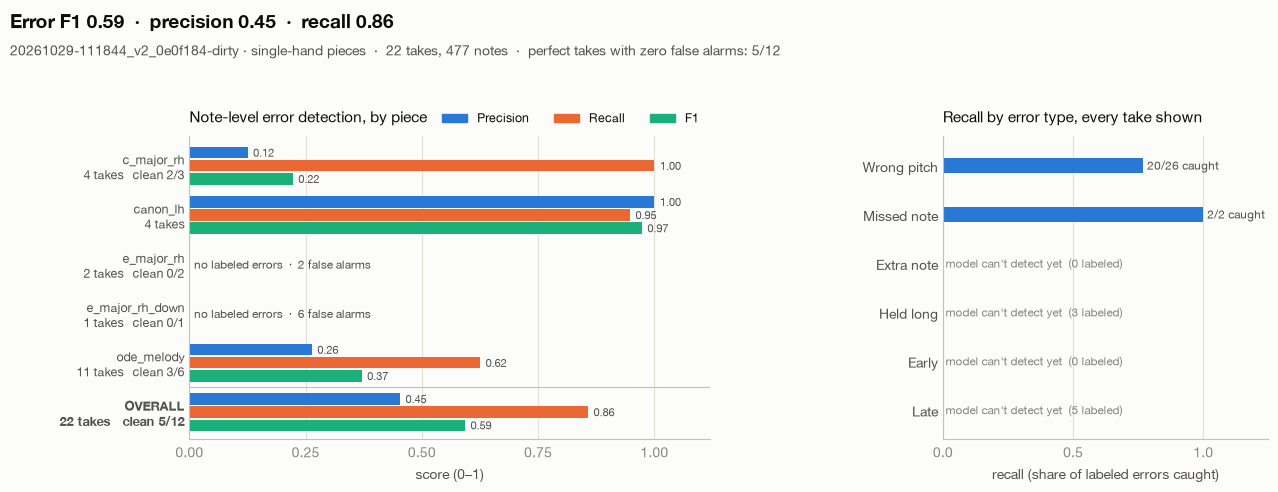

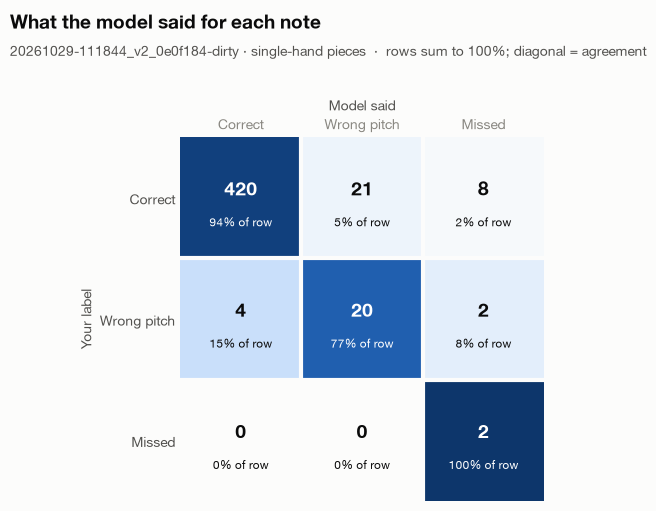

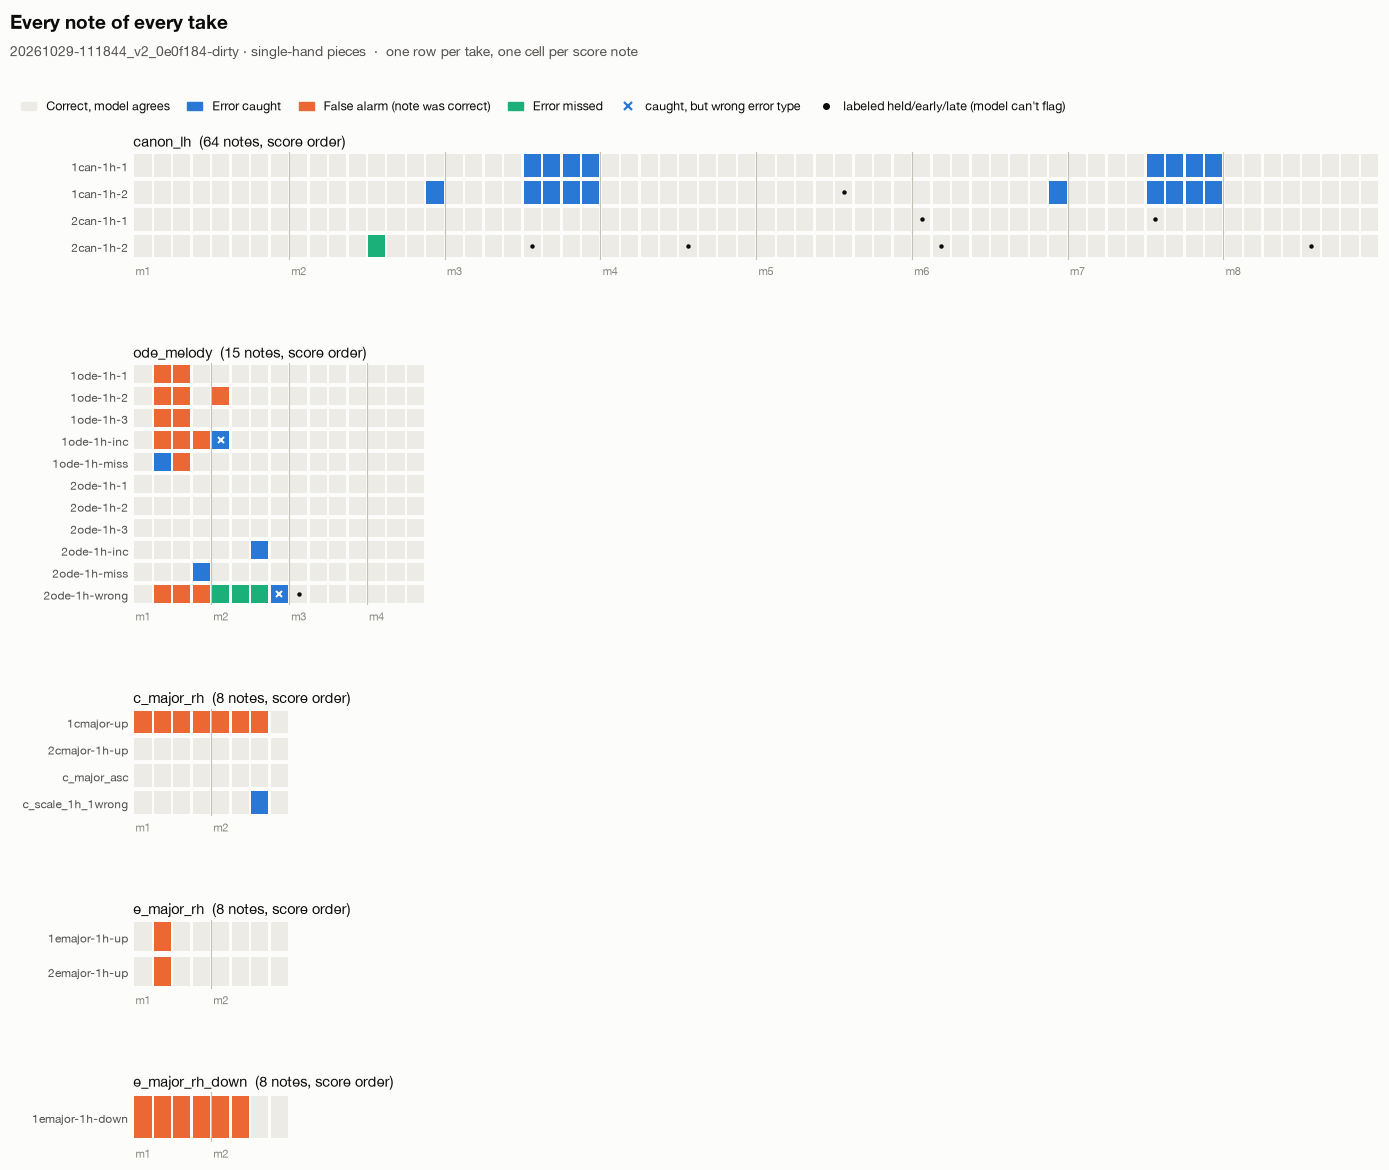

In [16]:
for fig in (plot_overview(mono, f"{run_dir.name} · single-hand pieces"),
            plot_confusion(mono, f"{run_dir.name} · single-hand pieces"),
            plot_note_map(mono_rows, f"{run_dir.name} · single-hand pieces")):
    display(fig); plt.close(fig)

**By take and false-alarm hotspots (single-hand only)**

In [17]:
mono_by_take = pd.DataFrame({t: summary_row(b) for t, b in mono["by_take"].items()}).T
mono_by_take.insert(0, "piece", mono_notes.groupby("take")["piece"].first())
mono_by_take["problems"] = mono_by_take["false alarms"] + mono_by_take["missed errors"]
display(mono_by_take.sort_values(["problems", "piece"], ascending=[False, True])
        [["piece", "notes", "false alarms", "missed errors", "error F1", "pass/fail acc"]].infer_objects().round(2))

display(hot[hot["piece"].isin(MONO_PIECES)].sort_values("false alarms", ascending=False)
        .head(15).reset_index(drop=True))

,piece,notes,false alarms,missed errors,error F1,pass/fail acc
1cmajor-up,c_major_rh,8,7,0,0.00,0.0
1emajor-1h-down,e_major_rh_down,8,6,0,0.00,0.0
2ode-1h-wrong,ode_melody,15,3,3,0.25,1.0
1ode-1h-2,ode_melody,15,3,0,0.00,0.0
1ode-1h-inc,ode_melody,15,3,0,0.40,1.0
1ode-1h-1,ode_melody,15,2,0,0.00,0.0
1ode-1h-3,ode_melody,15,2,0,0.00,0.0
2can-1h-2,canon_lh,64,0,1,0.00,0.0
1emajor-1h-up,e_major_rh,8,1,0,0.00,0.0
2emajor-1h-up,e_major_rh,8,1,0,0.00,0.0


,piece,note_id,pitch,measure,beat,false alarms,takes of piece
0,ode_melody,RH3,F4,1,3.0,6,11
1,ode_melody,RH2,E4,1,2.0,5,11
2,ode_melody,RH4,G4,1,4.0,2,11
3,e_major_rh,RH2,F#4,1,2.0,2,2
4,c_major_rh,RH1,C4,1,1.0,1,4
5,e_major_rh_down,RH3,C#5,1,3.0,1,1
6,e_major_rh_down,RH6,G#4,2,2.0,1,1
7,e_major_rh_down,RH5,A4,2,1.0,1,1
8,e_major_rh_down,RH4,B4,1,4.0,1,1
9,e_major_rh_down,RH2,D#5,1,2.0,1,1
